<a href="https://colab.research.google.com/github/rwalden-gif/IntroToML/blob/main/Homework6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import	torch
import	torch.nn	as	nn
import	pandas	as	pd
import	matplotlib.pyplot	as	plt
from	sklearn.model_selection	import	train_test_split
from	sklearn.preprocessing	import	StandardScaler
from	sklearn.linear_model	import	LinearRegression,	LogisticRegression
from	sklearn.svm	import	SVR,	SVC
from	sklearn.metrics	import	mean_squared_error,	r2_score
from	sklearn.metrics	import	accuracy_score,	precision_score,	recall_score,	f1_score
from	sklearn.metrics	import	ConfusionMatrixDisplay
housing_url	=	"https://raw.githubusercontent.com/rwalden-gif/IntroToML/main/Housing.csv"
cancer_url	=	"https://raw.githubusercontent.com/rwalden-gif/IntroToML/main/Cancer.csv"

In [13]:
data	=	pd.read_csv(housing_url)
for	col	in	["mainroad",	"guestroom",	"basement",	"hotwaterheating",	"airconditioning",	"prefarea"]:
  data[col]	=	(data[col]	==	"yes").astype(int)
data	=	pd.get_dummies(data,	columns=["furnishingstatus"],	drop_first=True,	dtype=int)

data	=	data.sample(frac=1,	random_state=42)
split	=	int(0.8	*	len(data))
train	=	data[:split]
test	=	data[split:]

scaler	=	StandardScaler().fit(train.drop(columns="price"))
X_train	=	torch.tensor(scaler.transform(train.drop(columns="price")),	dtype=torch.float32)
X_test	=	torch.tensor(scaler.transform(test.drop(columns="price")),	dtype=torch.float32)
y_train	=	torch.tensor(train["price"].values	/	1000000,	dtype=torch.float32)
y_test	=	torch.tensor(test["price"].values	/	1000000,	dtype=torch.float32)

print("Inputs:",	X_train.shape[1])
print("Training	rows:",	len(X_train),	"Test	rows:",	len(X_test))

Inputs: 13
Training	rows: 436 Test	rows: 109


In [14]:
def	make_net(n_inputs,	hidden):
  return	nn.Sequential(
    nn.Linear(n_inputs,	hidden),	nn.ReLU(),
    nn.Linear(hidden,	hidden),	nn.ReLU(),
    nn.Linear(hidden,	1))

def	train_housing(hidden,	lr,	epochs,	X_a,	y_a,	X_b,	y_b):
  torch.manual_seed(42)
  net	=	make_net(X_a.shape[1],	hidden)
  optimizer	=	torch.optim.Adam(net.parameters(),	lr=lr)
  loss_fn	=	nn.MSELoss()
  train_losses,	val_losses	=	[],	[]
  for	epoch	in	range(epochs):
    loss	=	loss_fn(net(X_a).squeeze(1),	y_a)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    with	torch.no_grad():
      train_losses.append(loss_fn(net(X_a).squeeze(1),	y_a).item())
      val_losses.append(loss_fn(net(X_b).squeeze(1),	y_b).item())
  return	net,	train_losses,	val_losses

In [15]:
cut	=	int(0.8	*	len(X_train))
best_loss	=	1e9
for	hidden	in	[8,	16,	32]:
  for	lr	in	[0.01,	0.001]:
    net,	train_losses,	val_losses	=	train_housing(hidden,	lr,	100,	X_train[:cut],	y_train[:cut],	X_train[cut:],	y_train[cut:])
    print("Neurons	per	hidden	layer",	hidden,	"learning	rate",	lr,	"validation	loss",	round(val_losses[-1],	4))
    if	val_losses[-1]	<	best_loss:
      best_loss	=	val_losses[-1]
      best_hidden	=	hidden
      best_lr	=	lr
print()
print("Chosen	neurons	per	hidden	layer:",	best_hidden)
print("Chosen	learning	rate:",	best_lr)

Neurons	per	hidden	layer 8 learning	rate 0.01 validation	loss 1.235
Neurons	per	hidden	layer 8 learning	rate 0.001 validation	loss 19.3099
Neurons	per	hidden	layer 16 learning	rate 0.01 validation	loss 0.9965
Neurons	per	hidden	layer 16 learning	rate 0.001 validation	loss 11.2582
Neurons	per	hidden	layer 32 learning	rate 0.01 validation	loss 1.1502
Neurons	per	hidden	layer 32 learning	rate 0.001 validation	loss 1.304

Chosen	neurons	per	hidden	layer: 16
Chosen	learning	rate: 0.01


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


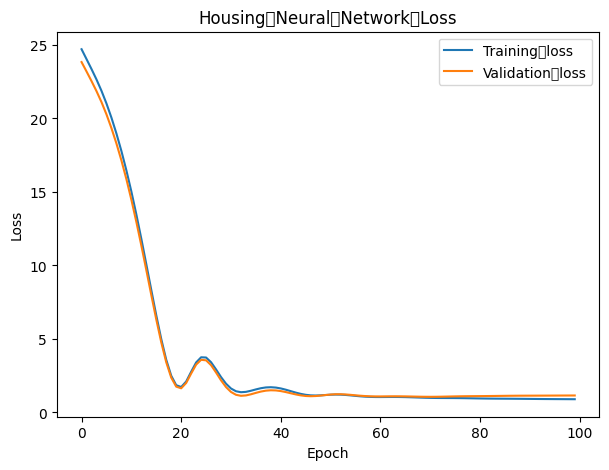

In [16]:
net,	train_losses,	val_losses	=	train_housing(best_hidden,	best_lr,	100,	X_train,	y_train,	X_test,	y_test)
plt.figure(figsize=(7,	5))
plt.plot(train_losses,	label="Training	loss")
plt.plot(val_losses,	label="Validation	loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Housing	Neural	Network	Loss")
plt.legend()
plt.show()

In [17]:
nn_pred	=	net(X_test).squeeze(1).detach().numpy()	*	1000000
true_price	=	y_test.numpy()	*	1000000

mse	=	mean_squared_error(true_price,	nn_pred)
print("Neural	network	MSE:",	mse)
print("Neural	network	RMSE:",	mse	**	0.5)
print("Neural	network	R2:",	r2_score(true_price,	nn_pred))

Neural	network	MSE: 1154430533632.0
Neural	network	RMSE: 1074444.2906135246
Neural	network	R2: 0.6712900996208191


In [18]:
linear	=	LinearRegression().fit(X_train,	y_train)
svr	=	SVR().fit(X_train,	y_train)

linear_pred	=	linear.predict(X_test)	*	1000000
svr_pred	=	svr.predict(X_test)	*	1000000

print("Model															MSE												RMSE									R2")
for	name,	pred	in	[("Neural	network",	nn_pred),	("Linear	regression",	linear_pred),	("SVR",	svr_pred)]:
    mse	=	mean_squared_error(true_price,	pred)
    print(f"{name:18s}	{mse:.4e}			{mse	**	0.5:,.0f}			{r2_score(true_price,	pred):.4f}")

Model															MSE												RMSE									R2
Neural	network    	1.1544e+12			1,074,444			0.6713
Linear	regression 	1.2417e+12			1,114,322			0.6464
SVR               	1.5286e+12			1,236,356			0.5648


In [19]:
cancer = pd.read_csv(cancer_url)
labels = (cancer["diagnosis"] == "M").astype(int).values
features = cancer.iloc[:, 2:-1].values

X_train_raw,	X_test_raw,	y_train_c,	y_test_c	=	train_test_split(features,	labels,	test_size=0.2,	random_state=42,	stratify=labels)

scaler	=	StandardScaler().fit(X_train_raw)
X_train_c	=	torch.tensor(scaler.transform(X_train_raw),	dtype=torch.float32)
X_test_c	=	torch.tensor(scaler.transform(X_test_raw),	dtype=torch.float32)
y_train_t	=	torch.tensor(y_train_c,	dtype=torch.float32)
y_test_t	=	torch.tensor(y_test_c,	dtype=torch.float32)

print("Inputs:",	X_train_c.shape[1])
print("Training	rows:",	len(X_train_c),	"Test	rows:",	len(X_test_c))

Inputs: 30
Training	rows: 455 Test	rows: 114


In [20]:
def	train_cancer(hidden,	lr,	epochs,	X_a,	y_a,	X_b,	y_b):
				torch.manual_seed(42)
				net	=	make_net(X_a.shape[1],	hidden)
				optimizer	=	torch.optim.Adam(net.parameters(),	lr=lr)
				loss_fn	=	nn.BCEWithLogitsLoss()
				train_losses,	val_losses,	train_accs,	val_accs	=	[],	[],	[],	[]
				for	epoch	in	range(epochs):
								loss	=	loss_fn(net(X_a).squeeze(1),	y_a)
								optimizer.zero_grad()
								loss.backward()
								optimizer.step()
								with	torch.no_grad():
												out_a	=	net(X_a).squeeze(1)
												out_b	=	net(X_b).squeeze(1)
												train_losses.append(loss_fn(out_a,	y_a).item())
												val_losses.append(loss_fn(out_b,	y_b).item())
												train_accs.append(((out_a	>	0).float()	==	y_a).float().mean().item())
												val_accs.append(((out_b	>	0).float()	==	y_b).float().mean().item())
				return	net,	train_losses,	val_losses,	train_accs,	val_accs

In [24]:
cut = int(0.8 * len(X_train_c))
X_fit, y_fit = X_train_c[:cut], y_train_t[:cut]
X_val, y_val = X_train_c[cut:], y_train_t[cut:]
best_loss = 1e9
for hidden in [8, 16, 32]:
		for lr in [0.01, 0.001]:
				net, train_losses, val_losses, train_accs, val_accs = train_cancer(
						hidden, lr, 100, X_fit, y_fit, X_val, y_val)
				loss = val_losses[-1]
				print("Neurons", hidden, "learning rate", lr, "validation loss", round(loss, 4))
				if loss < best_loss:
						best_loss = loss
						best_hidden_c = hidden
						best_lr_c = lr
print()
print("Chosen neurons per hidden layer:", best_hidden_c)
print("Chosen learning rate:", best_lr_c)

Neurons 8 learning rate 0.01 validation loss 0.1287
Neurons 8 learning rate 0.001 validation loss 0.2739
Neurons 16 learning rate 0.01 validation loss 0.123
Neurons 16 learning rate 0.001 validation loss 0.1755
Neurons 32 learning rate 0.01 validation loss 0.1637
Neurons 32 learning rate 0.001 validation loss 0.1043

Chosen neurons per hidden layer: 32
Chosen learning rate: 0.001


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


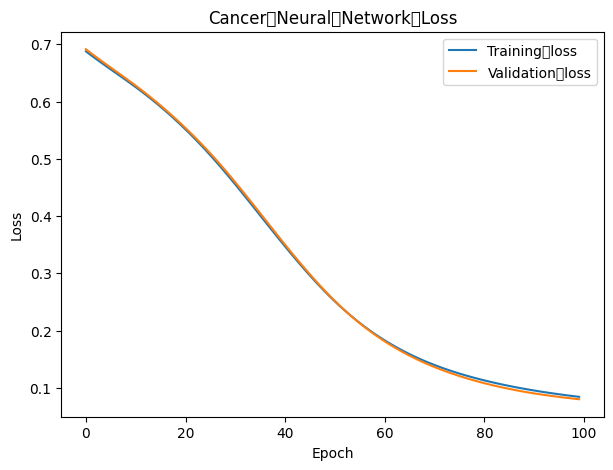

In [25]:
net_c,	train_losses,	val_losses,	train_accs,	val_accs	=	train_cancer(best_hidden_c,	best_lr_c,	100,	X_train_c,	y_train_t,	X_test_c,
y_test_t)

plt.figure(figsize=(7,	5))
plt.plot(train_losses,	label="Training	loss")
plt.plot(val_losses,	label="Validation	loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Cancer	Neural	Network	Loss")
plt.legend()
plt.show()

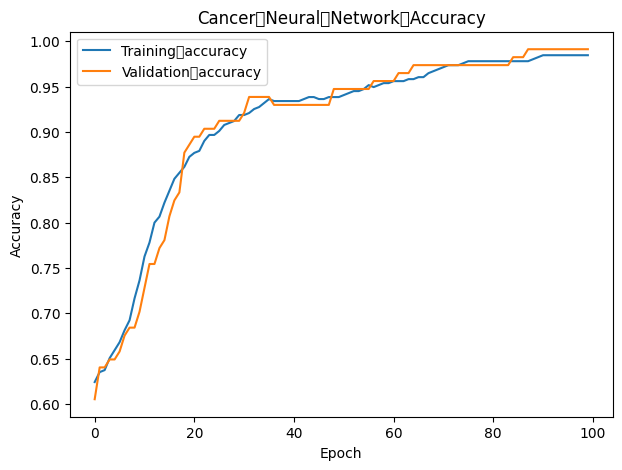

In [26]:
plt.figure(figsize=(7,	5))
plt.plot(train_accs,	label="Training	accuracy")
plt.plot(val_accs,	label="Validation	accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Cancer	Neural	Network	Accuracy")
plt.legend()
plt.show()

Neural	network	accuracy: 0.9912280701754386
Neural	network	precision: 1.0
Neural	network	recall: 0.9761904761904762
Neural	network	F1: 0.9879518072289156


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


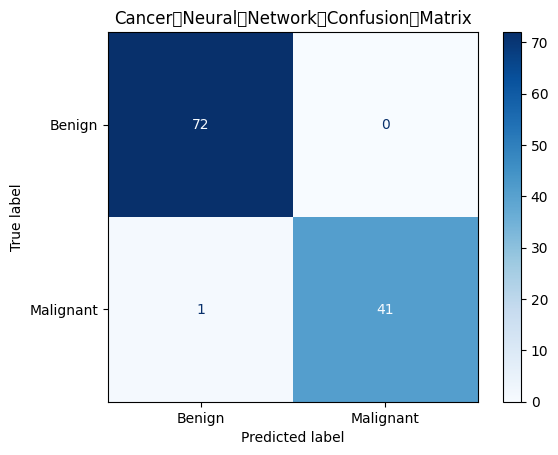

In [27]:
nn_labels	=	(net_c(X_test_c).squeeze(1)	>	0).int().numpy()

print("Neural	network	accuracy:",	accuracy_score(y_test_c,	nn_labels))
print("Neural	network	precision:",	precision_score(y_test_c,	nn_labels))
print("Neural	network	recall:",	recall_score(y_test_c,	nn_labels))
print("Neural	network	F1:",	f1_score(y_test_c,	nn_labels))

ConfusionMatrixDisplay.from_predictions(y_test_c,	nn_labels,	display_labels=["Benign",	"Malignant"],	cmap="Blues")
plt.title("Cancer	Neural	Network	Confusion	Matrix")
plt.show()

In [29]:
logistic = LogisticRegression(max_iter=1000).fit(X_train_c, y_train_c)
svm = SVC().fit(X_train_c, y_train_c)

logistic_labels = logistic.predict(X_test_c)
svm_labels = svm.predict(X_test_c)

models = [("Neural network", nn_labels), ("Logistic regression", logistic_labels),
          ("SVM", svm_labels)]

print("Model Accuracy Precision Recall F1")
for name, pred in models:
    accuracy = accuracy_score(y_test_c, pred)
    precision = precision_score(y_test_c, pred)
    recall = recall_score(y_test_c, pred)
    f1 = f1_score(y_test_c, pred)
    print(f"{name:19s} {accuracy:.4f} {precision:.4f} {recall:.4f} {f1:.4f}")

Model Accuracy Precision Recall F1
Neural network      0.9912 1.0000 0.9762 0.9880
Logistic regression 0.9649 0.9750 0.9286 0.9512
SVM                 0.9737 1.0000 0.9286 0.9630
